# Bitext: a look at the data before training on it

Nova's first fine-tune learns tone from the Bitext customer-support dataset (26,872 question and reply pairs,
27 intents, licence CDLA-Sharing 1.0). A model copies its training data's habits, so this notebook measures them first:

1. **Balance**: rows per intent and category
2. **Length**: reply length in Qwen3.5-2B tokens (not words)
3. **Duplicates**: exact, normalised, and same-first-12-words
4. **Placeholders**: the `{{...}}` slots, in replies and in customer messages
5. **Phrasing**: the dataset's variation flags (typos, colloquial, keyword mode...)

Plus the reply habits a model would pick up (openers, exclamation marks, numbered lists), and a seeded
5-rows-per-intent sample for reading by hand. Every finding feeds a written decision in `data/DECISIONS.md`.

Runs on a laptop CPU in about a minute: `uv sync --group data --group local-model`, then run all.

In [1]:
import collections, re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from datasets import load_dataset
from transformers import AutoTokenizer

pd.set_option("display.max_rows", 100, "display.width", 160, "display.max_colwidth", 120)
REPO = Path.cwd().parent if Path.cwd().name == "data_prep" else Path.cwd()
SEED = 3407

df = load_dataset("bitext/Bitext-customer-support-llm-chatbot-training-dataset", split="train").to_pandas()
tok = AutoTokenizer.from_pretrained("Qwen/Qwen3.5-2B")

df["resp_tokens"] = [len(ids) for ids in tok(df["response"].tolist()).input_ids]
df["inst_tokens"] = [len(ids) for ids in tok(df["instruction"].tolist()).input_ids]
df["resp_words"] = df["response"].str.split().map(len)
print(df.shape, "columns:", df.columns.tolist()[:5])

(26872, 8) columns: ['flags', 'instruction', 'category', 'intent', 'response']


## 1. Balance

In [2]:
counts = df.groupby(["category", "intent"]).size().sort_values()
print(f"{df.intent.nunique()} intents in {df.category.nunique()} categories; "
      f"rows per intent: min {counts.min()}, max {counts.max()}")
counts.to_frame("rows")

27 intents in 11 categories; rows per intent: min 950, max 1000


rows
category     intent                        
CANCEL       check_cancellation_fee     950
SHIPPING     change_shipping_address    973
ACCOUNT      delete_account             995
             recover_password           995
ORDER        track_order                995
DELIVERY     delivery_options           995
ACCOUNT      create_account             997
SHIPPING     set_up_shipping_address    997
FEEDBACK     review                     997
ORDER        change_order               997
REFUND       check_refund_policy        997
             get_refund                 997
             track_refund               998
ORDER        place_order                998
             cancel_order               998
PAYMENT      check_payment_methods      999
             payment_issue              999
SUBSCRIPTION newsletter_subscription    999
DELIVERY     delivery_period            999
CONTACT      contact_human_agent        999
ACCOUNT      registration_problems      999
INVOICE      get_invoice                999
FEEDBACK     complaint                 1000
CONTACT      contact_customer_service  1000
ACCOUNT      switch_account            1000
             edit_account              1000
INVOICE      check_invoice             1000

Raw counts are flat (950 to 1,000 per intent), so the dataset is not imbalanced by row count.
The imbalance shows up after deduplication (section 3): some intents have far fewer *distinct* questions.

## 2. Length, in tokens

       resp_tokens  resp_words  inst_tokens
count      26872.0     26872.0      26872.0
mean         126.9       104.8         10.1
std           68.5        53.0          3.1
min           12.0         9.0          1.0
50%          104.0        90.0         10.0
90%          220.0       173.0         14.0
99%          366.0       300.0         19.0
max          486.0       402.0         24.0

tokens per word in replies: 1.21


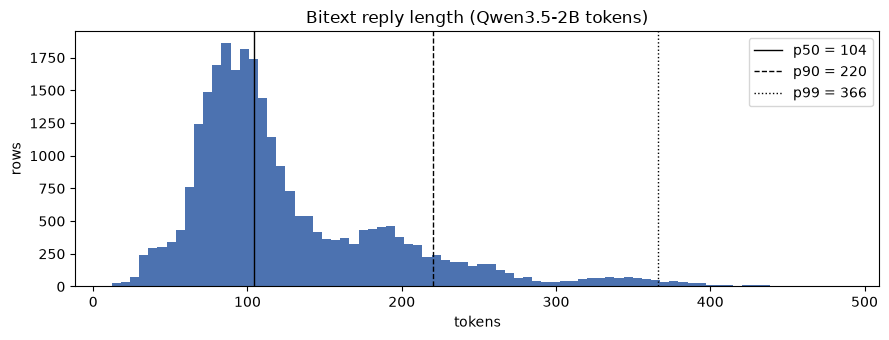

In [3]:
print(df[["resp_tokens", "resp_words", "inst_tokens"]].describe(percentiles=[.5, .9, .99]).round(1))
print(f"\ntokens per word in replies: {df.resp_tokens.sum() / df.resp_words.sum():.2f}")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(df.resp_tokens, bins=80, color="#4C72B0")
for q, ls in [(.5, "-"), (.9, "--"), (.99, ":")]:
    v = df.resp_tokens.quantile(q)
    ax.axvline(v, color="k", ls=ls, lw=1, label=f"p{int(q*100)} = {v:.0f}")
ax.set(title="Bitext reply length (Qwen3.5-2B tokens)", xlabel="tokens", ylabel="rows")
ax.legend(); plt.tight_layout(); plt.show()

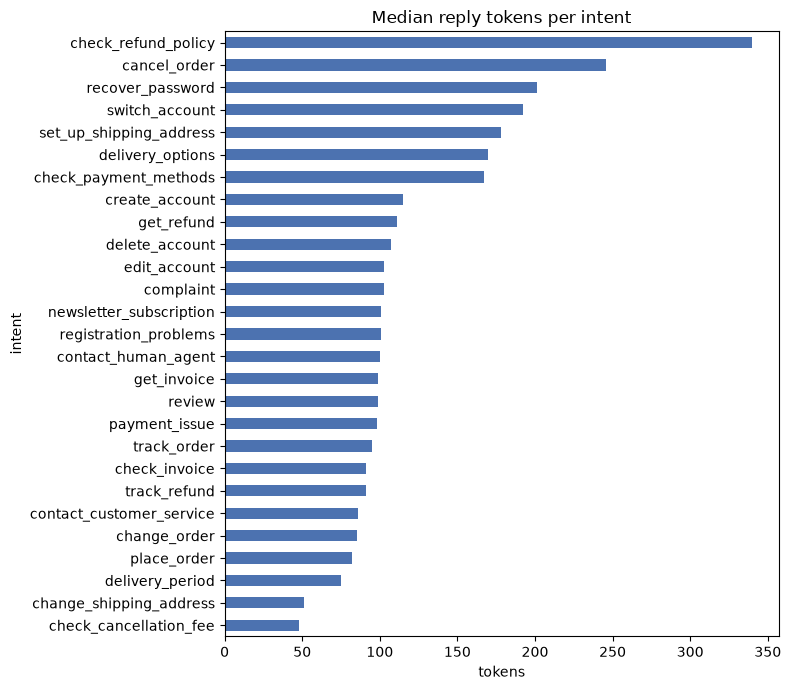

intent,check_cancellation_fee,change_shipping_address,delivery_period,place_order,change_order,contact_customer_service,track_refund,check_invoice,track_order,payment_issue,...,delete_account,get_refund,create_account,check_payment_methods,delivery_options,set_up_shipping_address,switch_account,recover_password,cancel_order,check_refund_policy
median,48.0,51.0,75.0,82.0,85.0,86.0,91.0,91.0,95.0,98.0,...,107.0,111.0,115.0,167.0,170.0,178.0,192.0,201.0,246.0,340.0
p90,77.0,114.0,97.0,148.0,116.0,112.0,125.0,142.0,117.0,130.0,...,174.0,160.0,152.0,211.0,227.0,231.0,232.0,249.0,277.0,392.0


In [4]:
by_intent = df.groupby("intent").resp_tokens.agg(median="median", p90=lambda s: s.quantile(.9)).sort_values("median")
ax = by_intent["median"].plot.barh(figsize=(8, 7), color="#4C72B0", title="Median reply tokens per intent")
ax.set_xlabel("tokens"); plt.tight_layout(); plt.show()
by_intent.T.round(0)

Median reply is about 104 tokens (90 words) and the 99th percentile is about 366. Lengths vary by intent by 7x:
`check_cancellation_fee` replies are short (median 48), `check_refund_policy` replies are long (median 340).
A model trained on all of it learns that some topics deserve an essay.

## 3. Duplicates

In [5]:
norm = (df.instruction.str.lower()
        .str.replace(r"[^a-z0-9 ]", "", regex=True)
        .str.replace(r"\s+", " ", regex=True).str.strip())
first12 = norm.str.split().str[:12].str.join(" ")
df["norm"], df["first12"] = norm, first12

print("exact duplicate questions:      ", df.instruction.duplicated().sum())
print("after normalising:              ", norm.duplicated().sum())
print("same first 12 words (includes the above):", first12.duplicated().sum())
print("exact duplicate replies:        ", df.response.duplicated().sum())
print("same normalised question under two intents:", (df.groupby("norm").intent.nunique() > 1).sum())

exact duplicate questions:       2237
after normalising:               2888
same first 12 words (includes the above): 3108
exact duplicate replies:         2
same normalised question under two intents: 0


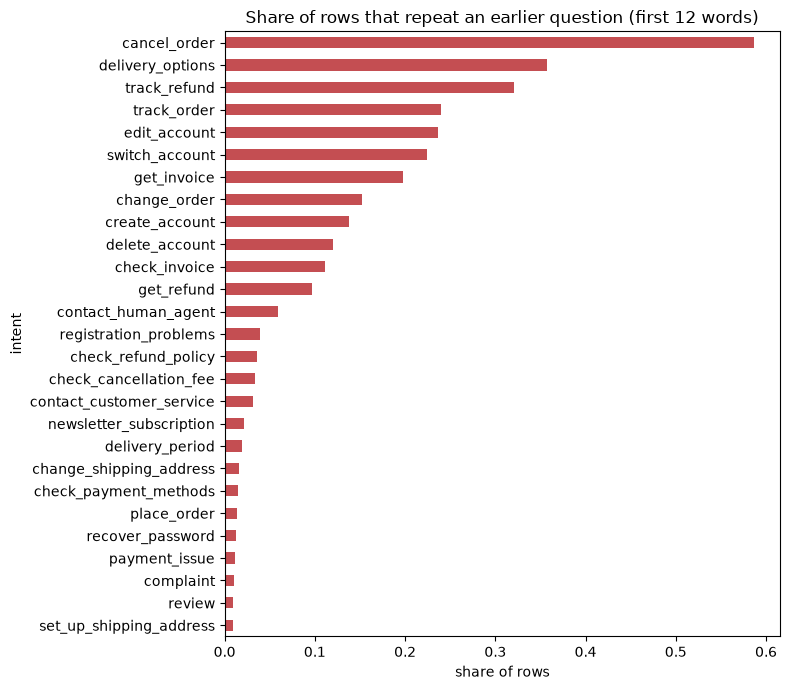

,rows,duplicates,distinct
intent,,,
cancel_order,998,585,413
delivery_options,995,355,640
track_refund,998,320,678
track_order,995,239,756
edit_account,1000,236,764
switch_account,1000,224,776
get_invoice,999,198,801
change_order,997,152,845
create_account,997,137,860


In [6]:
dup_rate = df.assign(dup=first12.duplicated()).groupby("intent").dup.mean().sort_values()
ax = dup_rate.plot.barh(figsize=(8, 7), color="#C44E52", title="Share of rows that repeat an earlier question (first 12 words)")
ax.set_xlabel("share of rows"); plt.tight_layout(); plt.show()
(df.assign(dup=first12.duplicated()).groupby("intent")
   .agg(rows=("dup", "size"), duplicates=("dup", "sum"))
   .assign(distinct=lambda t: t.rows - t.duplicates).sort_values("distinct"))

In [7]:
# What a duplicate cluster looks like: the most repeated cancel_order question
top = df[df.intent == "cancel_order"].first12.value_counts().index[0]
df[df.first12 == top][["instruction", "flags"]].head(8)

,instruction,flags
129,is it possible to cancel purchase {{Order Number}} ?,BILZ
145,is it possible to cancel purchase {{Order Number}},BILQ
218,is it possible to cancel purchase {{Order Number}}?,BIL
234,is it possible to cancel purchase {{Order Number}},BILQ
310,is it possible to cancel purchase {{Order Number}},BILQ
483,is it possible to cancel purchase {{Order Number}}?,BIL
590,is it possible to cancel purchase {{Order Number}}?,BIL
761,is it possible to cancel purchase {{Order Number}}?,BIL


Duplicates sit almost entirely in a few intents: 59% of `cancel_order` rows repeat an earlier question, so it
has about 410 distinct questions where the raw count says 998. No question appears under two intents, so there
are no label conflicts to resolve. Replies are all unique, which means the same question carries many different
replies: deduplicating on the question keeps the first reply and loses the rest.

## 4. Placeholders

391 distinct placeholders; 13006 of 26872 replies contain at least one


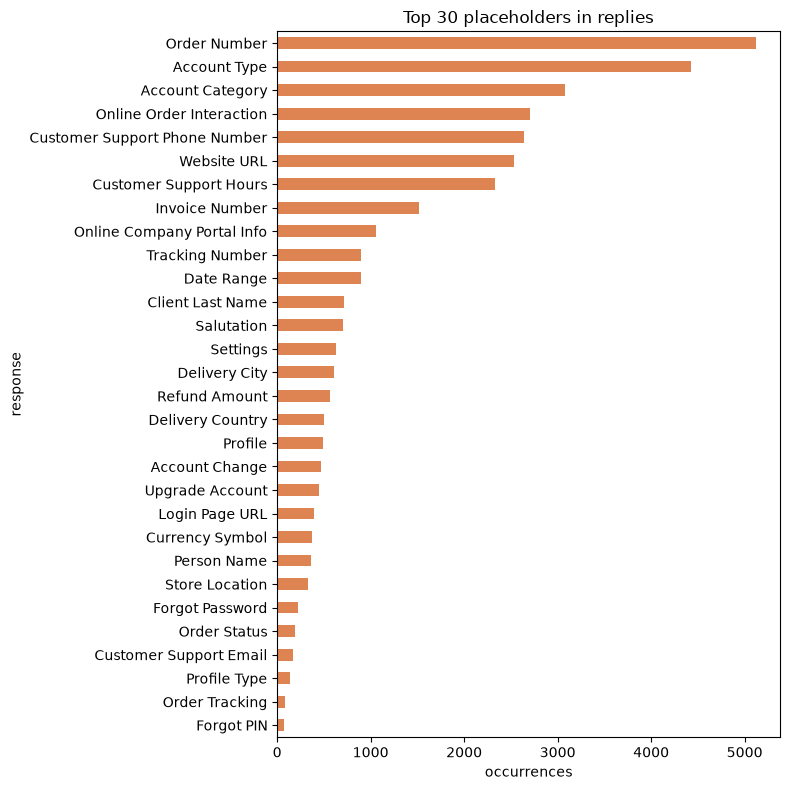

In [8]:
ph = df.response.str.findall(r"\{\{(.+?)\}\}").explode().value_counts()
print(f"{len(ph)} distinct placeholders; {df.response.str.contains(r'{{', regex=False).sum()} of "
      f"{len(df)} replies contain at least one")
ax = ph.head(30)[::-1].plot.barh(figsize=(8, 8), color="#DD8452", title="Top 30 placeholders in replies")
ax.set_xlabel("occurrences"); plt.tight_layout(); plt.show()

In [9]:
df["n_ph"] = df.response.str.count(r"\{\{")
df.groupby("intent").n_ph.mean().sort_values(ascending=False).round(2).to_frame("placeholders per reply").T

intent,cancel_order,switch_account,delivery_options,delivery_period,check_invoice,get_invoice,track_order,recover_password,delete_account,create_account,...,complaint,contact_human_agent,registration_problems,place_order,set_up_shipping_address,check_payment_methods,review,newsletter_subscription,check_cancellation_fee,change_shipping_address
placeholders per reply,8.09,6.16,2.46,1.9,1.9,1.8,1.64,1.58,1.52,1.51,...,0.25,0.25,0.15,0.14,0.13,0.12,0.05,0.03,0.0,0.0


In [10]:
# Customer messages carry placeholders too: a real customer would type a real order number here
ph_in = df.instruction.str.findall(r"\{\{(.+?)\}\}").explode().value_counts()
print(df.instruction.str.contains("{{", regex=False).sum(), "customer messages contain a placeholder")
print(ph_in.to_string())
df[df.instruction.str.contains("{{", regex=False)].sample(5, random_state=SEED)[["intent", "instruction"]]

6670 customer messages contain a placeholder
instruction
Order Number        2907
Account Type        1011
Person Name          887
Account Category     822
Refund Amount        624
Currency Symbol      372
Delivery City        234
Delivery Country     177
Invoice Number         8


,intent,instruction
4163,check_invoice,where to take aq quick look at the invoices from {{Person Name}}?
3973,check_invoice,I don't know what to do to look for my bill from {{Person Name}}
4015,check_invoice,I want assistance to see my invoices from {{Person Name}}
1553,change_order,need to add an item to purchase {{Order Number}} could ya help m
11907,delivery_options,do you ship to {{Delivery City}}?


Nearly half the replies (13,006) contain a placeholder, and there are 391 kinds. They are not evenly spread:
a `cancel_order` reply has about 8 of them, which is where the menu paths ("{{Online Order Interaction}}") live.
A quarter of customer messages also carry one (`{{Order Number}}`, `{{Person Name}}`, `{{Refund Amount}}`).
Those are the customer's own details, not facts Nova invents, so they need a different rule from the reply side.

## 5. Phrasing flags

In [11]:
FLAG_NAMES = {  # from the dataset card
    "B": "basic syntax", "L": "synonyms / lexical", "M": "morphological", "I": "interrogative",
    "C": "coordinated", "N": "negation", "P": "politeness", "Q": "colloquial", "W": "offensive",
    "K": "keyword mode", "E": "abbreviations", "Z": "errors and typos",
    "S": "(not documented in the card)", "V": "(not documented in the card)",
}
letters = collections.Counter(c for f in df["flags"] for c in set(f))
flag_table = (pd.DataFrame([(k, FLAG_NAMES.get(k, "?"), v) for k, v in letters.items()],
                           columns=["flag", "meaning", "rows"])
              .assign(share=lambda t: (t.rows / len(df)).round(3)).sort_values("rows", ascending=False))
flag_table

,flag,meaning,rows,share
0,B,basic syntax,26872,1.000
3,L,synonyms / lexical,24115,0.897
2,Q,colloquial,8968,0.334
7,I,interrogative,7839,0.292
1,Z,errors and typos,5286,0.197
8,M,morphological,4920,0.183
4,C,coordinated,2646,0.098
10,K,keyword mode,2227,0.083
5,E,abbreviations,1882,0.070
9,P,politeness,1329,0.049


In [12]:
for flag in ["N", "S", "V", "W", "K"]:
    print(f"--- {flag}: {FLAG_NAMES[flag]}")
    for s in df[df["flags"].str.contains(flag)].instruction.sample(4, random_state=SEED):
        print("   ", s)

--- N: negation
    I cannot remove some products from purchase {{Order Number}}
    I can no longer afford purchase {{Order Number}}
    I do not want the item I purchased, can I cancel the order?
    i cannot remove some fucking items from order {{Order Number}}
--- S: (not documented in the card)
    can i place an order from {{Delivery Country}}
    do you ship  to {{Delivery Country}}?
    is it possible to order from {{Delivery City}}?
    shipmetns to {{Delivery City}}
--- V: (not documented in the card)
    I cannot pay for the last purchase I have made, cancel it
    I have paid {{Currency Symbol}}{{Refund Amount}} for a purchase, where to obtain a rebate?
    I have lost bill #00108, can you show it to me?
    i have paid {{Currency Symbol}}{{Refund Amount}} for an article i want an refund
--- W: offensive
    I need to edit my bloody user, will you help me?
    how do i locate my goddamn invoicesfrom {{Person Name}}
    how do I modify the goddamn details included on my prof

Every row has `B`, and most have `L`. The rare types are negation (`N`, 463 rows, 1.7%), the undocumented `S`
(417, all of them `delivery_options` questions about shipping to a place) and `V` (77, statements
about something already done: "I have paid ..."), offensive (`W`, 1,288) and politeness (`P`, 1,329). These are the phrasings the golden set
should include so that a fine-tune that only handles clean questions does not look better than it is.

## 6. Reply habits

In [13]:
no_ph = df.response.str.replace(r"\{\{.+?\}\}", "", regex=True)
habits = {
    "contains an exclamation mark": df.response.str.contains("!", regex=False),
    "numbered list": df.response.str.contains(r"\n\s*\d+\.", regex=True),
    "markdown bold": df.response.str.contains("**", regex=False),
    "a digit outside placeholders": no_ph.str.contains(r"\d", regex=True),
    "longer than 70 words": df.resp_words > 70,
}
print(pd.DataFrame({k: [v.mean().round(3)] for k, v in habits.items()}, index=["share of replies"]).T)
print("\nMost common first three words:")
print(df.response.str.split().str[:3].str.join(" ").value_counts().head(12).to_string())

                              share of replies
contains an exclamation mark             0.542
numbered list                            0.232
markdown bold                            0.052
a digit outside placeholders             0.237
longer than 70 words                     0.764

Most common first three words:


response
Thank you for         3525
I'm sorry to           801
We appreciate your     643
We understand your     610
We understand that     557
I appreciate your      475
I understand your      461
I'll do my             370
I'll get right         370
I'll take care         370
I'm on it!             370
I'm happy to           369


Over half the replies contain an exclamation mark, almost a quarter have a numbered list, and 76% are longer
than 70 words (the most Nova's rewritten replies will be allowed). "Thank you for" opens 13% of all replies. Several openers ("I'm on it!", "I'll take care") appear
exactly 370 times each, a sign of a generation template: the model would learn those exact phrases.

## 7. Reading sample

Five seeded rows per intent (135 rows), written to `data/eda/reading_sample.md` (outside Git, because it is
Bitext text). Read every one and write one line per intent in `data/DECISIONS.md`: what a good Nova reply
would do differently. Charts show how much; only reading shows what.

In [14]:
sample = df.groupby("intent").sample(5, random_state=SEED).sort_values(["category", "intent"])
out = REPO / "data" / "eda" / "reading_sample.md"
out.parent.mkdir(parents=True, exist_ok=True)
lines = ["# Bitext reading sample (5 rows per intent, seed 3407)", ""]
for intent, g in sample.groupby("intent", sort=False):
    lines += [f"## {intent} ({g.category.iloc[0]})", ""]
    for _, r in g.iterrows():
        lines += [f"**Customer** [{r['flags']}]: {r.instruction}", "",
                  f"**Reply** ({r.resp_tokens} tokens):", "", r.response, "", "---", ""]
out.write_text("\n".join(lines))
print(f"wrote {len(sample)} rows to {out.relative_to(REPO)}")

wrote 135 rows to data/eda/reading_sample.md
